In [1]:
import pandas as pd
import numpy as np

In [2]:
file_path = "CH2O_09337_DFRS_DS95_2021_272_00_57/calibrated/ch2o_frs_calibrated_01_21272001904.csv"

df = pd.read_csv(file_path, header=None)

df.columns = [
    "Day",
    "Time",
    "Frequency",
    "Value_1",
    "Value_2",
    "Signal"
]

df.head()

,Day,Time,Frequency,Value_1,Value_2,Signal
0,2021-272,1144.00000,2.240000e+09,2.239989e+09,2.239989e+09,17.477752
1,2021-272,1144.08192,2.240000e+09,2.239989e+09,2.239989e+09,17.492057
2,2021-272,1144.16384,2.240000e+09,2.239989e+09,2.239989e+09,17.385770
3,2021-272,1144.24576,2.240000e+09,2.239989e+09,2.239989e+09,17.296193
4,2021-272,1144.32768,2.240000e+09,2.239989e+09,2.239989e+09,17.574878


In [3]:
df["Landing_Score"] = (
    df["Signal"] - df["Signal"].min()
) / (
    df["Signal"].max() - df["Signal"].min()
)

In [4]:
df["Ice_Probability"] = df["Landing_Score"] * 100

In [5]:
mean_signal = df["Signal"].mean()
std_signal = df["Signal"].std()

df["Anomaly_Score"] = (
    abs(df["Signal"] - mean_signal)
) / std_signal

In [6]:
df["Final_Score"] = (
    0.4 * df["Landing_Score"]
    +
    0.4 * (df["Ice_Probability"] / 100)
    +
    0.2 * (
        df["Anomaly_Score"] /
        df["Anomaly_Score"].max()
    )
)

In [7]:
top_sites = df.sort_values(
    by="Final_Score",
    ascending=False
).head(20)

top_sites

,Day,Time,Frequency,Value_1,Value_2,Signal,Landing_Score,Ice_Probability,Anomaly_Score,Final_Score
6030,2021-272,1637.977588,2.240000e+09,2.240200e+09,2.239988e+09,211780.448691,1.000000,100.000000,9.492050,1.000000
6031,2021-272,1638.059508,2.240000e+09,2.240200e+09,2.239988e+09,211780.443540,1.000000,99.999998,9.492049,1.000000
6032,2021-272,1638.141428,2.240000e+09,2.240200e+09,2.239988e+09,211780.438323,1.000000,99.999996,9.492049,1.000000
6033,2021-272,1638.223348,2.240000e+09,2.240200e+09,2.239988e+09,211780.433040,1.000000,99.999995,9.492049,1.000000
6034,2021-272,1638.305268,2.240000e+09,2.240200e+09,2.239988e+09,211780.427693,1.000000,99.999993,9.492049,1.000000
6035,2021-272,1638.387188,2.240000e+09,2.240200e+09,2.239988e+09,211780.422280,1.000000,99.999991,9.492048,1.000000
6036,2021-272,1638.469108,2.240000e+09,2.240200e+09,2.239988e+09,211780.416803,1.000000,99.999989,9.492048,1.000000
6037,2021-272,1638.551028,2.240000e+09,2.240200e+09,2.239988e+09,211780.411261,1.000000,99.999987,9.492048,1.000000
6038,2021-272,1638.632948,2.240000e+09,2.240200e+09,2.239988e+09,211780.405653,1.000000,99.999985,9.492048,1.000000
6039,2021-272,1638.714868,2.240000e+09,2.240200e+09,2.239988e+09,211780.399981,1.000000,99.999983,9.492047,1.000000


In [8]:
top_sites.to_csv(
    "final_landing_sites.csv",
    index=False
)

print("Final Landing Sites Saved")

Final Landing Sites Saved


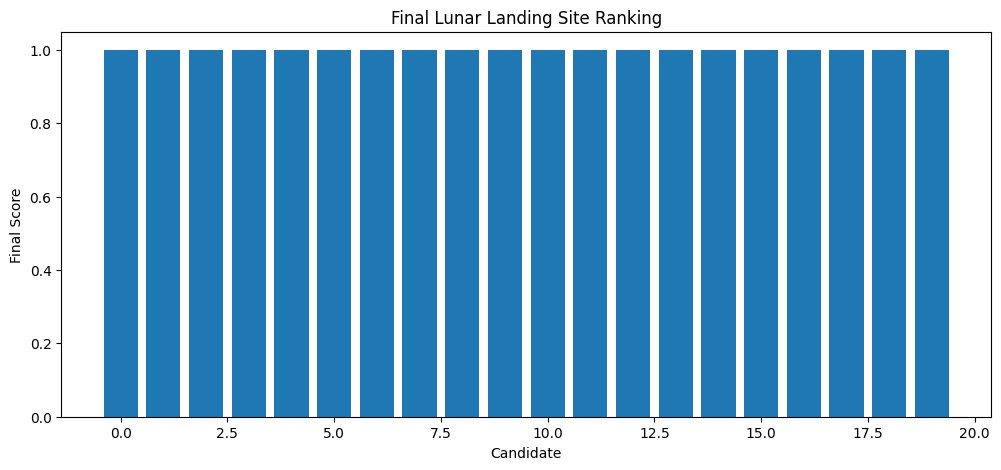

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.bar(
    range(len(top_sites)),
    top_sites["Final_Score"]
)

plt.title("Final Lunar Landing Site Ranking")
plt.xlabel("Candidate")
plt.ylabel("Final Score")

plt.show()